K MEANS

   Study_Hours  Marks  Cluster
0            1     35        0
1            2     40        0
2            3     45        0
3            4     50        0
4            5     55        0
5            6     65        1
6            7     70        1
7            8     75        1
8            9     85        1
9           10     90        1
Centroids:
[[ 3. 45.]
 [ 8. 77.]]


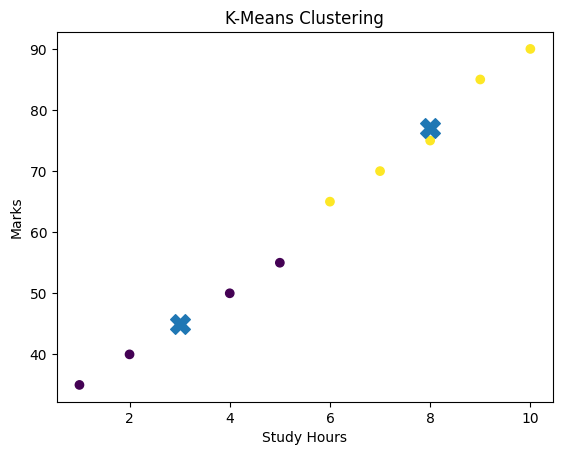

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Data
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [35, 40, 45, 50, 55, 65, 70, 75, 85, 90]
}

df = pd.DataFrame(data)

# K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(df[["Study_Hours", "Marks"]])

print(df)

# Cluster centers
print("Centroids:")
print(kmeans.cluster_centers_)

# Plot
plt.scatter(
    df["Study_Hours"],
    df["Marks"],
    c=df["Cluster"]
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("K-Means Clustering")
plt.show()



K MEANS

   Study_Hours  Marks  Cluster
0            1     35        0
1            2     40        0
2            3     45        0
3            4     50        0
4            5     55        1
5            6     65        1
6            7     70        1
7            8     75        1
8            9     85        1
9           10     90        1

Medoids:
[[ 2 40]
 [ 7 70]]


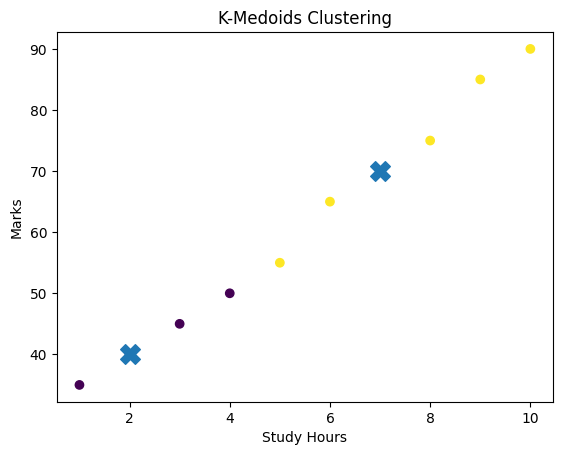

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [35, 40, 45, 50, 55, 65, 70, 75, 85, 90]
}

df = pd.DataFrame(data)

# Convert data to array
X = df[["Study_Hours", "Marks"]].values

# Number of clusters
k = 2

# Select initial medoids
medoids = np.array([0, 5])


# Calculate distance
def distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


# K-Medoids algorithm
for _ in range(10):

    # Assign each point to nearest medoid
    clusters = []

    for point in X:
        distances = [
            distance(point, X[m])
            for m in medoids
        ]

        clusters.append(np.argmin(distances))

    clusters = np.array(clusters)

    # Update medoids
    new_medoids = []

    for cluster in range(k):

        points = np.where(clusters == cluster)[0]

        best_medoid = points[0]
        best_cost = float("inf")

        for candidate in points:

            cost = sum(
                distance(X[candidate], X[p])
                for p in points
            )

            if cost < best_cost:
                best_cost = cost
                best_medoid = candidate

        new_medoids.append(best_medoid)

    new_medoids = np.array(new_medoids)

    # Stop if medoids do not change
    if np.array_equal(medoids, new_medoids):
        break

    medoids = new_medoids


# Add clusters to dataframe
df["Cluster"] = clusters

print(df)

# Display medoids
print("\nMedoids:")
print(X[medoids])


# Plot
plt.scatter(
    df["Study_Hours"],
    df["Marks"],
    c=df["Cluster"]
)

plt.scatter(
    X[medoids, 0],
    X[medoids, 1],
    marker="X",
    s=200
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("K-Medoids Clustering")

plt.show()

